In [1]:
# Data Manipulation and Analysis  
import pandas as pd  
import numpy as np  
  
# Data Visualization  
import matplotlib.pyplot as plt  
import seaborn as sns  
  
# Statistical Analysis  
from scipy import stats  
from scipy.stats import norm, skew, kurtosis  
  
# Warnings  
import warnings  
warnings.filterwarnings('ignore')  
  
# Display Settings  
pd.set_option('display.max_columns', None)  
pd.set_option('display.max_rows', 100)  
pd.set_option('display.float_format', lambda x: '%.3f' % x)  
  
# Plot Style  
plt.style.use('seaborn-v0_8-whitegrid')  
sns.set_palette('husl')  
plt.rcParams['figure.figsize'] = (12, 6)  
plt.rcParams['font.size'] = 12  
  
print("✅ Libraries imported successfully!")  

✅ Libraries imported successfully!


In [2]:
# Load the Titanic dataset from seaborn's built-in datasets  
df = sns.load_dataset('titanic')  
  
# Create a copy for manipulation  
df_original = df.copy()  
  
# Display basic information  
print(f"Dataset Shape: {df.shape}")  
print(f"Number of Rows: {df.shape[0]}")  
print(f"Number of Columns: {df.shape[1]}")  
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB")  

Dataset Shape: (891, 15)
Number of Rows: 891
Number of Columns: 15
Memory Usage: 278.87 KB


In [3]:
# Display comprehensive dataset info  
print("📋 Dataset Information:")  
df.info()

📋 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
# Separate numerical and categorical columns  
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()  
categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()  
  
print("🔢 Numerical Columns:")  
print(numerical_cols)  
print(f"\n📝 Categorical Columns:")  
print(categorical_cols) 

🔢 Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

📝 Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [5]:
# Statistical summary for numerical columns  
print("📊 Statistical Summary - Numerical Features:")  
df.describe().T 

📊 Statistical Summary - Numerical Features:


,count,mean,std,min,25%,50%,75%,max
survived,891.000,0.384,0.487,0.000,0.000,0.000,1.000,1.000
pclass,891.000,2.309,0.836,1.000,2.000,3.000,3.000,3.000
age,714.000,29.699,14.526,0.420,20.125,28.000,38.000,80.000
sibsp,891.000,0.523,1.103,0.000,0.000,0.000,1.000,8.000
parch,891.000,0.382,0.806,0.000,0.000,0.000,0.000,6.000
fare,891.000,32.204,49.693,0.000,7.910,14.454,31.000,512.329


In [6]:
# Extended statistics with additional percentiles  
print("📊 Extended Statistical Summary:")  
df.describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T 

📊 Extended Statistical Summary:


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
survived,891.000,0.384,0.487,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000,1.000
pclass,891.000,2.309,0.836,1.000,1.000,1.000,1.000,2.000,3.000,3.000,3.000,3.000,3.000,3.000
age,714.000,29.699,14.526,0.420,1.000,4.000,14.000,20.125,28.000,38.000,50.000,56.000,65.870,80.000
sibsp,891.000,0.523,1.103,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,3.000,5.000,8.000
parch,891.000,0.382,0.806,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2.000,2.000,4.000,6.000
fare,891.000,32.204,49.693,0.000,0.000,7.225,7.550,7.910,14.454,31.000,77.958,112.079,249.006,512.329


In [ ]:
# Statistical summary for categorical columns  
print("📊 Statistical Summary - Categorical Features:")  
df.describe(include=['object', 'category', 'bool']).T

📊 Statistical Summary - Categorical Features:


,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537


In [8]:
def detailed_statistics(df, column):  
    """  
    Calculate detailed statistics for a numerical column.  
      
    Parameters:  
    -----------  
    df : pandas DataFrame  
    column : str - column name  
      
    Returns:  
    --------  
    dict : Dictionary containing all statistics  
    """  
    data = df[column].dropna()  
      
    stats = {  
        'Count': len(data),  
        'Missing': df[column].isnull().sum(),  
        'Missing %': (df[column].isnull().sum() / len(df)) * 100,  
        'Mean': data.mean(),  
        'Median': data.median(),  
        'Mode': data.mode().iloc[0] if len(data.mode()) > 0 else np.nan,  
        'Std Dev': data.std(),  
        'Variance': data.var(),  
        'Min': data.min(),  
        'Max': data.max(),  
        'Range': data.max() - data.min(),  
        'Q1 (25%)': data.quantile(0.25),  
        'Q2 (50%)': data.quantile(0.50),  
        'Q3 (75%)': data.quantile(0.75),  
        'IQR': data.quantile(0.75) - data.quantile(0.25),  
        'Skewness': data.skew(),  
        'Kurtosis': data.kurtosis(),  
        'Coef. of Variation': (data.std() / data.mean()) * 100  
    }  
      
    return stats  
  
# Example usage  
for col in numerical_cols:  
    print(f"\n{'='*50}")  
    print(f"📊 Statistics for: {col.upper()}")  
    print('='*50)  
    stats = detailed_statistics(df, col)  
    for key, value in stats.items():  
        if isinstance(value, float):  
            print(f"  {key:20}: {value:>12.4f}")  
        else:  
            print(f"  {key:20}: {value:>12}") 


📊 Statistics for: SURVIVED
  Count               :          891
  Missing             :            0
  Missing %           :       0.0000
  Mean                :       0.3838
  Median              :       0.0000
  Mode                :            0
  Std Dev             :       0.4866
  Variance            :       0.2368
  Min                 :            0
  Max                 :            1
  Range               :            1
  Q1 (25%)            :       0.0000
  Q2 (50%)            :       0.0000
  Q3 (75%)            :       1.0000
  IQR                 :       1.0000
  Skewness            :       0.4785
  Kurtosis            :      -1.7750
  Coef. of Variation  :     126.7701

📊 Statistics for: PCLASS
  Count               :          891
  Missing             :            0
  Missing %           :       0.0000
  Mean                :       2.3086
  Median              :       3.0000
  Mode                :            3
  Std Dev             :       0.8361
  Variance           

In [9]:
# Calculate missing values  
def missing_values_analysis(df):  
    """  
    Comprehensive missing values analysis.  
      
    Parameters:  
    -----------  
    df : pandas DataFrame  
      
    Returns:  
    --------  
    pandas DataFrame : Missing values summary  
    """  
    missing_values = df.isnull().sum()  
    missing_percentage = (df.isnull().sum() / len(df)) * 100  
      
    missing_df = pd.DataFrame({  
        'Column': df.columns,  
        'Missing Values': missing_values.values,  
        'Percentage (%)': missing_percentage.values,  
        'Data Type': df.dtypes.values,  
        'Non-Null Count': df.notnull().sum().values  
    })  
      
    missing_df = missing_df.sort_values('Missing Values', ascending=False)  
    missing_df = missing_df.reset_index(drop=True)  
      
    return missing_df  
  
# Perform analysis  
missing_df = missing_values_analysis(df)  
print("📊 Missing Values Analysis:")  
print("=" * 70)  
print(missing_df.to_string(index=False))  

📊 Missing Values Analysis:
     Column  Missing Values  Percentage (%) Data Type  Non-Null Count
       deck             688          77.217  category             203
        age             177          19.865   float64             714
   embarked               2           0.224    object             889
embark_town               2           0.224    object             889
        sex               0           0.000    object             891
     pclass               0           0.000     int64             891
   survived               0           0.000     int64             891
       fare               0           0.000   float64             891
      parch               0           0.000     int64             891
      sibsp               0           0.000     int64             891
      class               0           0.000  category             891
 adult_male               0           0.000      bool             891
        who               0           0.000    object          

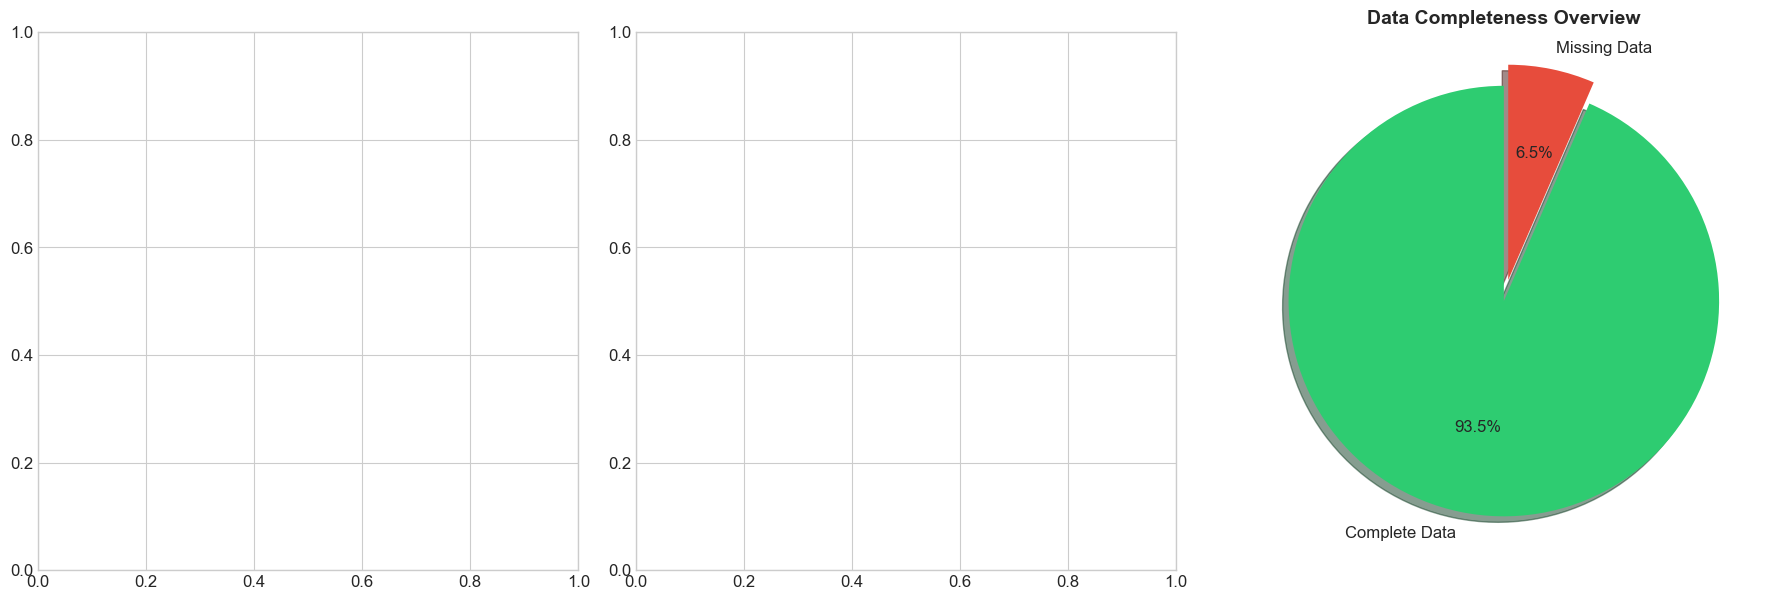

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

ax3 = axes[2]
total_cells = df.shape[0] * df.shape[1]
missing_cells = df.isnull().sum().sum()
complete_cells = total_cells - missing_cells

sizes = [complete_cells, missing_cells]
labels = ['Complete Data', 'Missing Data']
colors_pie = ['#2ecc71', '#e74c3c']
explode = (0, 0.1)

ax3.pie(sizes, explode=explode, labels=labels, colors=colors_pie,
autopct='%1.1f%%', shadow=True, startangle=90)
ax3.set_title('Data Completeness Overview', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('missing_values_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

📊 Missing Value Patterns:
Total unique patterns: 5

Top 5 most common patterns:
   survived  pclass  sex  age  sibsp  parch  fare  embarked  class  who  \
1         0       0    0    0      0      0     0         0      0    0   
0         0       0    0    0      0      0     0         0      0    0   
4         0       0    0    1      0      0     0         0      0    0   
3         0       0    0    1      0      0     0         0      0    0   
2         0       0    0    0      0      0     0         1      0    0   

   adult_male  deck  embark_town  alive  alone  count  
1           0     1            0      0      0    530  
0           0     0            0      0      0    182  
4           0     1            0      0      0    158  
3           0     0            0      0      0     19  
2           0     0            1      0      0      2  


<Axes: >

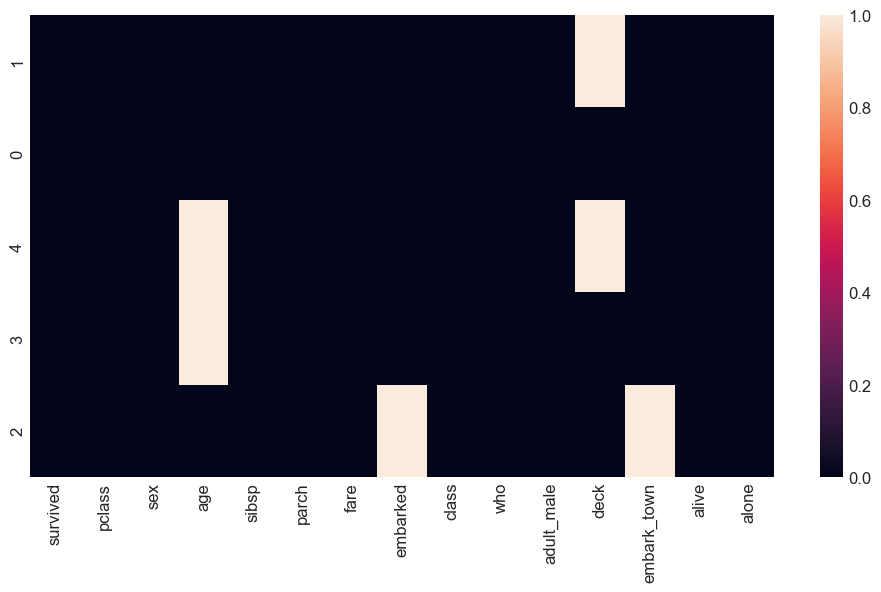

In [13]:
def missing_patterns(df):

    # Create a binary matrix (1 = missing, 0 = present)
    missing_matrix = df.isnull().astype(int)
    # Find unique patterns  
    patterns = missing_matrix.drop_duplicates()  
    pattern_counts = missing_matrix.groupby(list(missing_matrix.columns)).size().reset_index(name='count')  
    pattern_counts = pattern_counts.sort_values('count', ascending=False)  
    
    print("📊 Missing Value Patterns:")  
    print("=" * 60)  
    print(f"Total unique patterns: {len(patterns)}")  
    print(f"\nTop 5 most common patterns:")  
    print(pattern_counts.head())  
    
    return pattern_counts 

patterns = missing_patterns(df)


sns.heatmap(patterns.drop('count', axis=1))

In [ ]:
df.drop(columns=['deck'], inplace=True)
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])  
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])  

In [28]:
df['embarked'].mode()[0]

'S'

In [26]:
print("✅ Missing values handled!")  
print(f"Remaining missing values: {df.isnull().sum()}")  

✅ Missing values handled!
Remaining missing values: survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [30]:
def duplicate_analysis(df):  
    """  
    Comprehensive duplicate analysis.  
      
    Parameters:  
    -----------  
    df : pandas DataFrame  
      
    Returns:  
    --------  
    dict : Duplicate analysis results  
    """  
    # Exact duplicates  
    exact_duplicates = df.duplicated().sum()  
      
    # Duplicates keeping first  
    duplicates_keep_first = df.duplicated(keep='first').sum()  
      
    # Duplicates keeping last  
    duplicates_keep_last = df.duplicated(keep='last').sum()  
      
    results = {  
        'Total Rows': len(df),  
        'Exact Duplicates': exact_duplicates,  
        'Duplicate Percentage': (exact_duplicates / len(df)) * 100,  
        'Unique Rows': len(df) - exact_duplicates  
    }  
      
    return results  
  
# Perform analysis  
dup_results = duplicate_analysis(df)  
  
print("📊 Duplicate Values Analysis:")  
print("=" * 50)  
for key, value in dup_results.items():  
    if isinstance(value, float):  
        print(f"  {key:25}: {value:.2f}")  
    else:  
        print(f"  {key:25}: {value}")  


📊 Duplicate Values Analysis:
  Total Rows               : 891
  Exact Duplicates         : 116
  Duplicate Percentage     : 13.02
  Unique Rows              : 775


In [33]:
# Check duplicates in specific columns  
def check_column_duplicates(df, columns):  
    """  
    Check for duplicates in specific columns.  
    """  
    duplicates = df.duplicated(subset=columns, keep=False)  
    duplicate_rows = df[duplicates]  
      
    print(f"📊 Duplicates in columns: {columns}")  
    print(f"   Duplicate rows: {len(duplicate_rows)}")  
      
    return duplicate_rows  
  
# Example: Check duplicates by name (if exists)  
check_column_duplicates(df, df.columns)  

📊 Duplicates in columns: Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='object')
   Duplicate rows: 174


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
4,0,3,male,35.000,0,0,8.050,S,Third,man,True,Southampton,no,True
23,1,1,male,28.000,0,0,35.500,S,First,man,True,Southampton,yes,True
26,0,3,male,28.000,0,0,7.225,C,Third,man,True,Cherbourg,no,True
28,1,3,female,28.000,0,0,7.879,Q,Third,woman,False,Queenstown,yes,True
29,0,3,male,28.000,0,0,7.896,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,0,3,male,26.000,0,0,7.896,S,Third,man,True,Southampton,no,True
877,0,3,male,19.000,0,0,7.896,S,Third,man,True,Southampton,no,True
878,0,3,male,28.000,0,0,7.896,S,Third,man,True,Southampton,no,True
884,0,3,male,25.000,0,0,7.050,S,Third,man,True,Southampton,no,True


In [34]:
df.drop_duplicates(keep='first', inplace=True)

In [35]:
check_column_duplicates(df, df.columns)  

📊 Duplicates in columns: Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='object')
   Duplicate rows: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone


<Axes: xlabel='pclass', ylabel='count'>

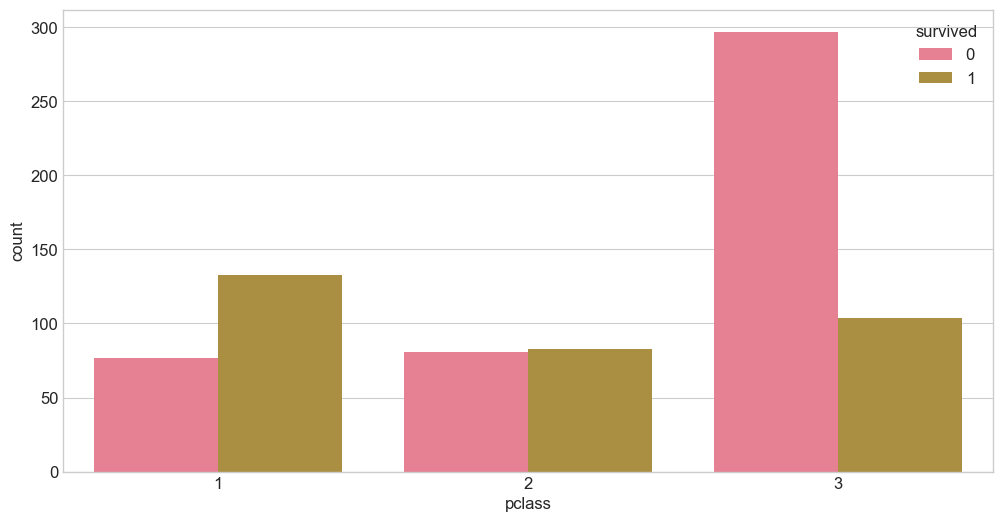

In [37]:
sns.countplot(data=df, x='pclass', hue='survived')